### Divergence measures for the CUSUM (LLR) pipeline

The data come from `simulate_w_cusum` / `cusum_analysis` in `CPA_with_AQUA.py` (T = 10 s, step at 5 s, 100 repeats). For each condition (noise variance, step height h, autapse f), the ISIs from all repeats are pooled into pre- and post-change references, and a distribution is fitted to each.
The measures below compare those two fitted distributions. They are properties of the **condition**, not of a single trial, so they describe how decodable the step is in principle. Units are nats.

| Column | Meaning |
|---|---|
| `KL post\|\|pre`, `KL pre\|\|post` | KL divergence in each direction, per ISI |
| `divergence` | Jeffreys divergence J = sum of the two KLs, per ISI |
| `divergence per s` | J weighted by the pre/post firing rates, per second |
| `JS divergence` | Jensen-Shannon divergence, per ISI, at most ln 2 (fully separable) |
| `fisher local` (`per s`) | Fisher information about the input current, J / h², from each condition's pre/post pair (nats/pA²). Only accurate for small h |
| `fisher` (`per s`) | Fisher information at I_0 + h, from the post distributions of neighbouring step heights |

`score per s` (the evidence actually collected in each trial) is shown at the end, for comparison with `divergence per s`.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *

In [29]:
tag = 'N100'
outfile = f'CPA_cusum_mean_{tag}_llr_pair_div.pickle'
SAVE = False
DROP_ZERO_NOISE = True      # at var = 0 the ISIs are almost fixed, so the fits are very narrow and divergences reach ~1e5

with open(outfile, 'rb') as file:
    data = pickle.load(file)
method = data['method'].iloc[0]
print(f"method: {method}, rows: {len(data)}")

if DROP_ZERO_NOISE:
    data = data[data['variance'] != 0.0]

# the divergence measures are the same for every repeat of a condition: keep one row per condition
cond_cols = ['variance', 'step_height', 'autapse f']
cond = data.drop_duplicates(cond_cols).reset_index(drop = True)

variances = np.sort(cond['variance'].unique())
f_vals = np.sort(cond['autapse f'].unique())
print(f"conditions: {len(cond)}, variances: {variances}, f: {f_vals}")

method: llr_pair, rows: 82500
conditions: 660, variances: [12.5 25.  37.5 50. ], f: [  0 100 150 200 220 240 260 280 300 350 400]


#### Example pre/post ISI distributions
Pooled ISIs before and after the step (from `CPA_cusum_mean_{tag}_spikes.pickle`) for a fixed input, with the autapse strength f increasing left to right. As f grows the neuron bursts: the short intra-burst ISIs barely move with the step, so the pre and post distributions overlap more and every divergence falls (JS, Jeffreys J and KS for each condition are shown in the corner of each panel).

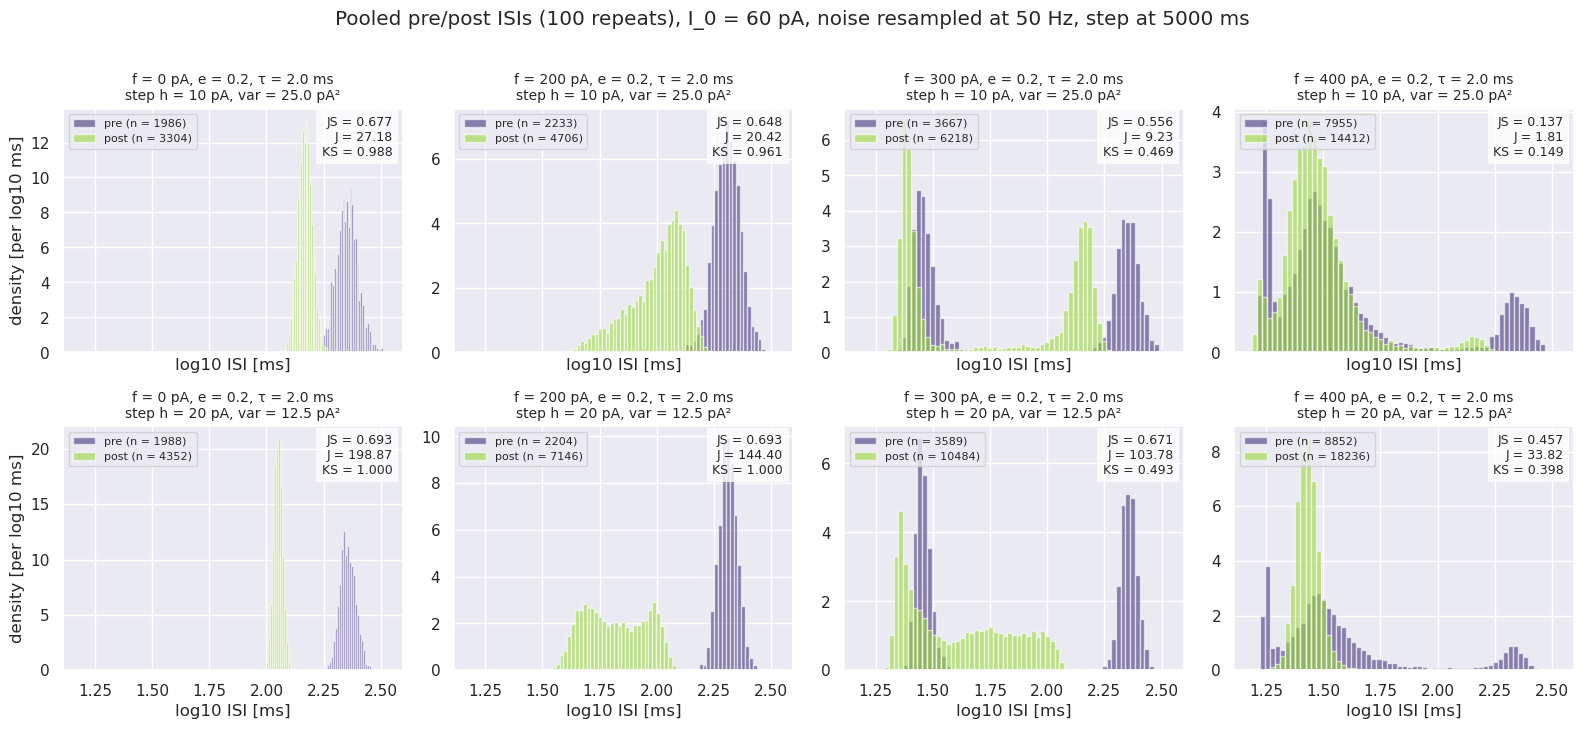

In [30]:
import inspect

# example pre/post ISI distributions: same input, increasing autapse strength
EXAMPLES = [(25.0, 10), (12.5, 20)]     # (variance, step height) rows
EXAMPLE_F = [0, 200, 300, 400]          # columns
T_DISCARD = 200                          # ms, as in simulate_w_cusum

with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    saved = pickle.load(file)
sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}

fig, ax = plt.subplots(len(EXAMPLES), len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.6*len(EXAMPLES)), sharex = True, squeeze = False)
for r, (v, h) in enumerate(EXAMPLES):
    for c, f in enumerate(EXAMPLE_F):
        trials = [spike_isis(saved['spikes'][(rep, v, h, f)], T_DISCARD) for rep in range(saved['N_repeats'])]
        pre, post = reference_isis(trials, saved['changepoint'])
        # histogram of log10(ISI), so the short burst ISIs and the long ISIs are both visible
        bins = np.linspace(np.log10(min(pre.min(), post.min())), np.log10(max(pre.max(), post.max())), 60)
        ax[r, c].hist(np.log10(pre), bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.15), label = f'pre (n = {len(pre)})')
        ax[r, c].hist(np.log10(post), bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.85), label = f'post (n = {len(post)})')
        ax[r, c].set_xlabel('log10 ISI [ms]')

        row = cond[(cond['variance'] == v) & (cond['step_height'] == h) & (cond['autapse f'] == f)].iloc[0]
        ax[r, c].set_title(f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\n'
                           f'step h = {h} pA, var = {v} pA²', fontsize = 10)
        ax[r, c].text(0.97, 0.97, f"JS = {row['JS divergence']:.3f}\nJ = {row['divergence']:.2f}\n"
                                  f"KS = {row['KS distance']:.3f}",
                      transform = ax[r, c].transAxes, ha = 'right', va = 'top', fontsize = 9,
                      bbox = dict(facecolor = 'white', alpha = 0.8, edgecolor = 'none'))
        ax[r, c].legend(loc = 'upper left', fontsize = 8)
    ax[r, 0].set_ylabel('density [per log10 ms]')
fig.suptitle(f'Pooled pre/post ISIs ({saved["N_repeats"]} repeats), I_0 = {sim["I_0"]} pA, '
             f'noise resampled at {sim["noise_rate"]} Hz, step at {saved["changepoint"]} ms', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_example_pre_post_ISIs.png', bbox_inches = 'tight')

#### Example pre/post ISI-pair distributions (`llr_pair`)
The `llr_pair` method fits 2D mixtures to consecutive ISI pairs (ISI$_{n-1}$, ISI$_n$), so these are the distributions it actually compares. Same neurons and conditions as the plot above: for each (variance, step height) there is a pre row and a post row, one column per autapse strength in `EXAMPLE_F`. Colour scale is log density, shared by all panels. JS and J (bottom right of the post panels) come from the fitted pair distributions.

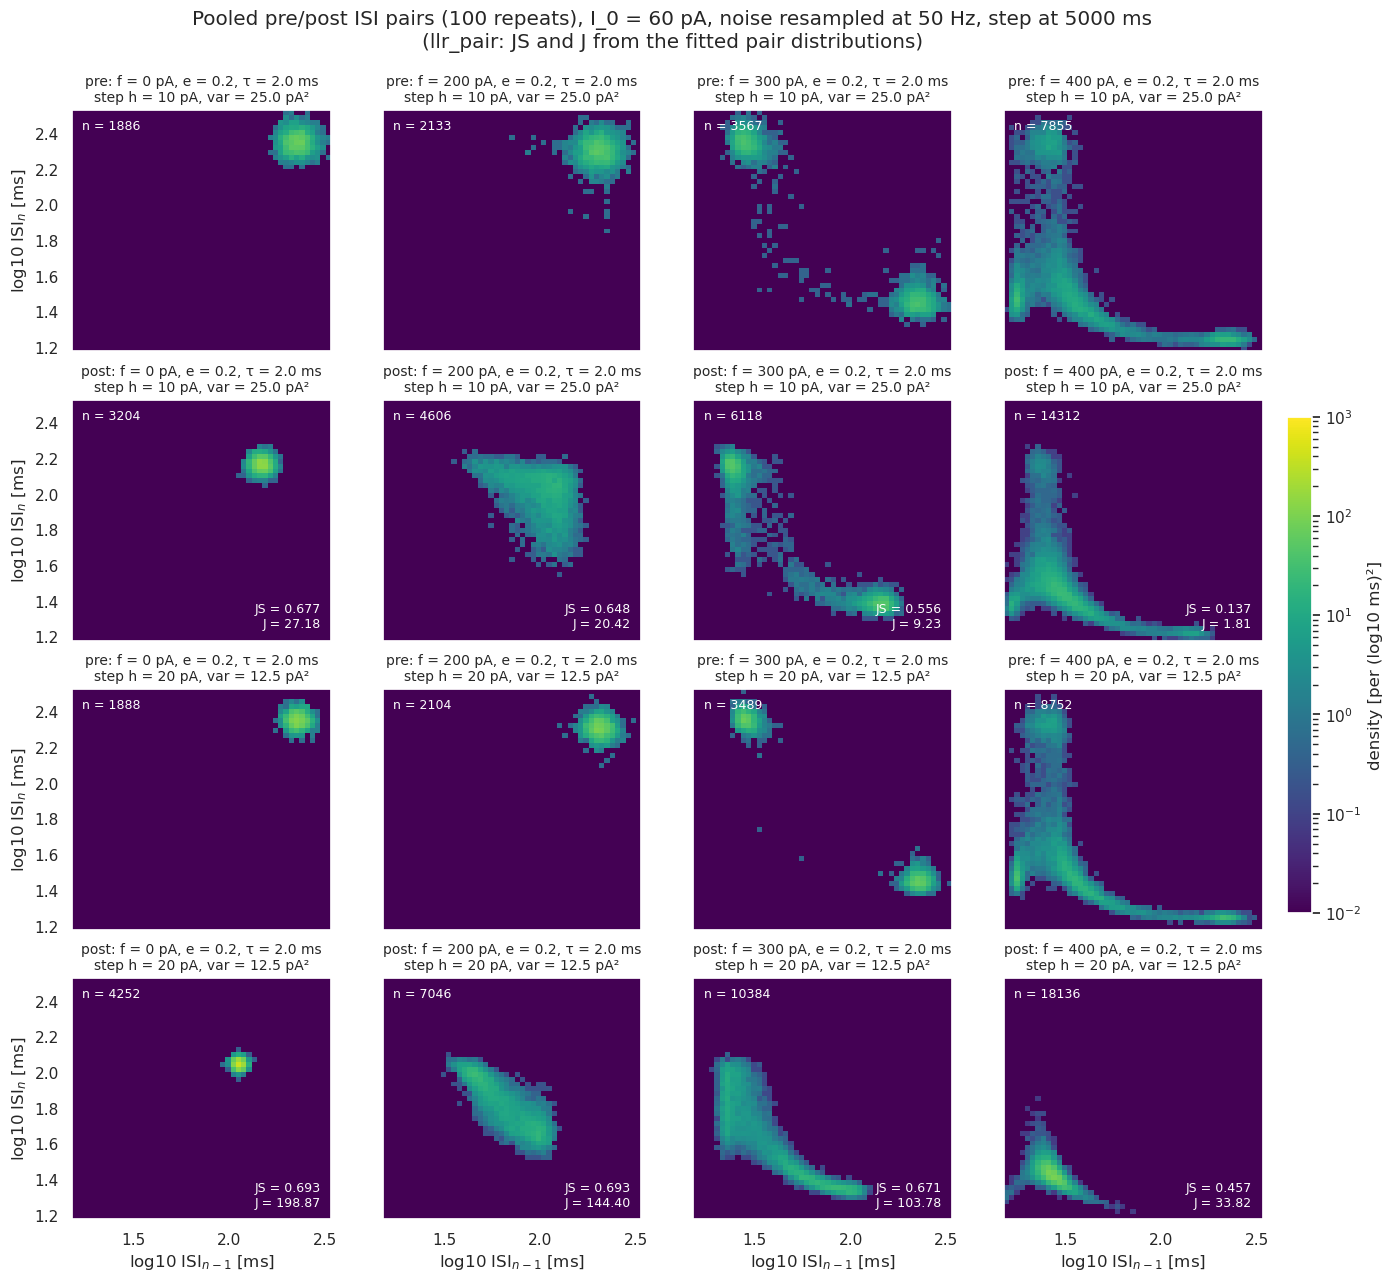

In [31]:
from matplotlib.colors import LogNorm

# llr_pair references: consecutive ISI pairs (ISI_{n-1}, ISI_n), for the same examples as above
# rows: pre and post for each (variance, step height); columns: EXAMPLE_F
pairs = {}
for v, h in EXAMPLES:
    for f in EXAMPLE_F:
        trials = [spike_isis(saved['spikes'][(rep, v, h, f)], T_DISCARD) for rep in range(saved['N_repeats'])]
        pairs[(v, h, f)] = [np.log10(p) for p in reference_pairs(trials, saved['changepoint'])]
lo = min(p.min() for pp in pairs.values() for p in pp if len(p))
hi = max(p.max() for pp in pairs.values() for p in pp if len(p))
bins = np.linspace(lo, hi, 50)
norm = LogNorm(vmin = 1e-2, vmax = 1e3)    # density per (log10 ms)², shared by all panels

fig, ax = plt.subplots(2*len(EXAMPLES), len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.6*2*len(EXAMPLES)),
                       sharex = True, sharey = True, squeeze = False)
for i, (v, h) in enumerate(EXAMPLES):
    for c, f in enumerate(EXAMPLE_F):
        row = cond[(cond['variance'] == v) & (cond['step_height'] == h) & (cond['autapse f'] == f)].iloc[0]
        for j, (name, p) in enumerate(zip(['pre', 'post'], pairs[(v, h, f)])):
            a = ax[2*i + j, c]
            *_, im = a.hist2d(p[:, 0], p[:, 1], bins = bins, density = True, cmap = 'viridis', norm = norm)
            a.set_facecolor(plt.cm.viridis(0))
            a.grid(False)
            a.set_title(f'{name}: f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\n'
                        f'step h = {h} pA, var = {v} pA²', fontsize = 10)
            a.text(0.04, 0.96, f'n = {len(p)}', transform = a.transAxes, ha = 'left', va = 'top',
                   fontsize = 9, color = 'white')
        ax[2*i + 1, c].text(0.96, 0.04, f"JS = {row['JS divergence']:.3f}\nJ = {row['divergence']:.2f}",
                            transform = ax[2*i + 1, c].transAxes, ha = 'right', va = 'bottom', fontsize = 9, color = 'white')
for a in ax[-1]:
    a.set_xlabel('log10 ISI$_{n-1}$ [ms]')
for a in ax[:, 0]:
    a.set_ylabel('log10 ISI$_n$ [ms]')
fig.colorbar(im, ax = ax, label = 'density [per (log10 ms)²]', fraction = 0.02, pad = 0.02)
fig.suptitle(f'Pooled pre/post ISI pairs ({saved["N_repeats"]} repeats), I_0 = {sim["I_0"]} pA, '
             f'noise resampled at {sim["noise_rate"]} Hz, step at {saved["changepoint"]} ms\n'
             f'({method}: JS and J from the fitted pair distributions)', y = 0.95)
if SAVE: plt.savefig(f'./plots/{tag}_example_pre_post_ISI_pairs.png', bbox_inches = 'tight')

In [32]:
# column -> (axis label, log y-axis)
MEASURES = {
    'divergence':          ('Jeffreys divergence [nats/ISI]', True),
    'divergence per s':    ('Jeffreys divergence [nats/s]', True),
    'KL post||pre':        ('KL(post || pre) [nats/ISI]', True),
    'KL pre||post':        ('KL(pre || post) [nats/ISI]', True),
    'JS divergence':       ('JS divergence [nats/ISI]', False),
    'fisher local':        ('Fisher info, local [nats/pA² ISI]', True),
    'fisher local per s':  ('Fisher info, local [nats/pA² s]', True),
    'fisher':              ('Fisher info, across steps [nats/pA² ISI]', True),
    'fisher per s':        ('Fisher info, across steps [nats/pA² s]', True),
}


def measure_by_variance(df, y, label, log = False):
    '''one panel per noise variance, one line per autapse strength'''
    fig, ax = plt.subplots(1, len(variances), figsize = (4*len(variances), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, v in enumerate(variances):
        fig, ax[n] = psychometric_curve(df[df['variance'] == v], x = 'step_height', y = y, hue = 'autapse f',
                                        fig = fig, ax = ax[n], add_colorbar = n == len(variances) - 1)
        ax[n].set_xlabel('Step Height [pA]')
        ax[n].set_title(f'Variance = {v}')
        if log:
            ax[n].set_yscale('log')
    ax[0].set_ylabel(label)
    fig.suptitle(f'{y} ({method})', y = 1.02)
    return fig, ax


def measure_by_neuron(df, y, label, log = False):
    '''one panel per autapse strength, one line per noise variance'''
    fig, ax = plt.subplots(1, len(f_vals), figsize = (2.2*len(f_vals), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, f in enumerate(f_vals):
        fig, ax[n] = psychometric_curve(df[df['autapse f'] == f], x = 'step_height', y = y, hue = 'variance',
                                        fig = fig, ax = ax[n], add_colorbar = n == len(f_vals) - 1,
                                        colorbar_label = 'Noise Variance')
        ax[n].set_xlabel('Step [pA]')
        ax[n].set_title(f'f = {np.round(f, 0)} pA')
        if log:
            ax[n].set_yscale('log')
    ax[0].set_ylabel(label)
    fig.suptitle(f'{y} ({method})', y = 1.04)
    return fig, ax

#### Each measure against step height, one panel per noise level
Lines are autapse strengths. A curve that rises faster means a step of a given size is easier to tell apart from no step.

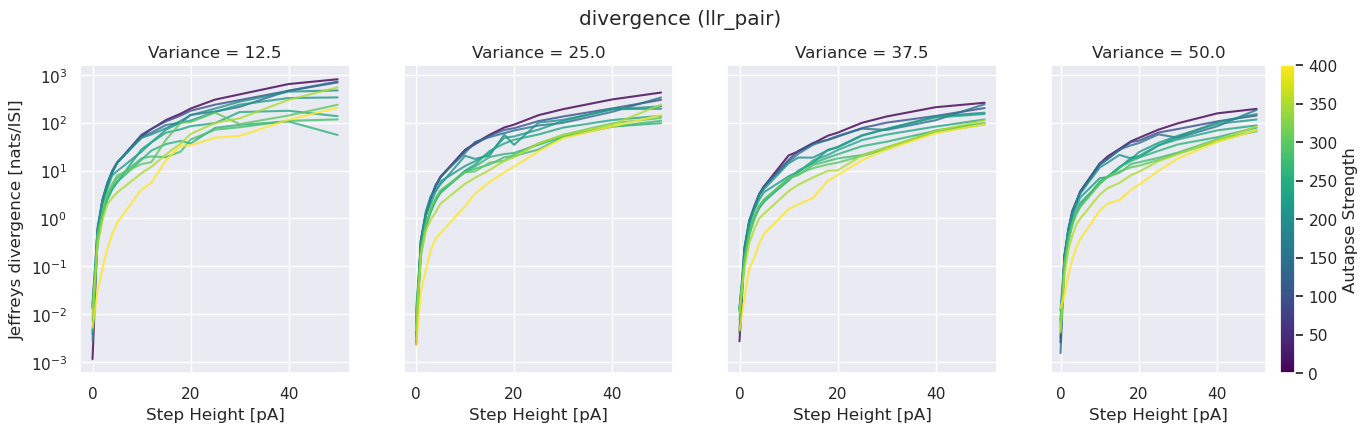

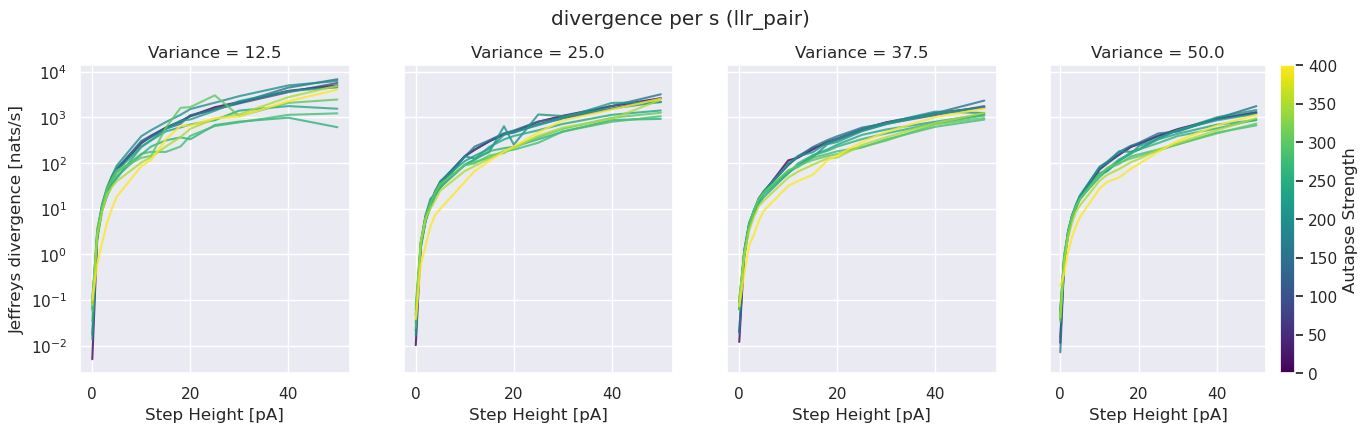

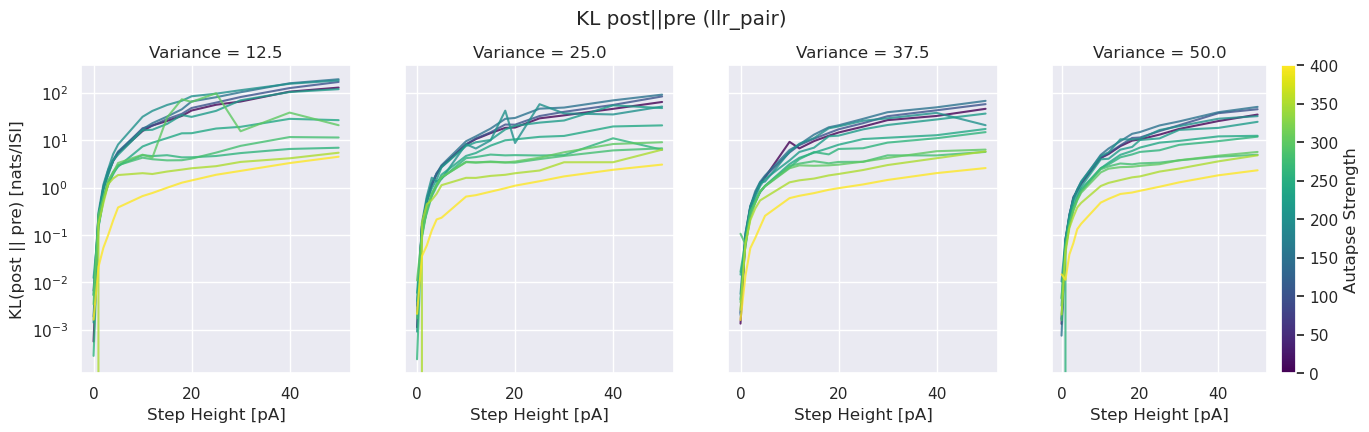

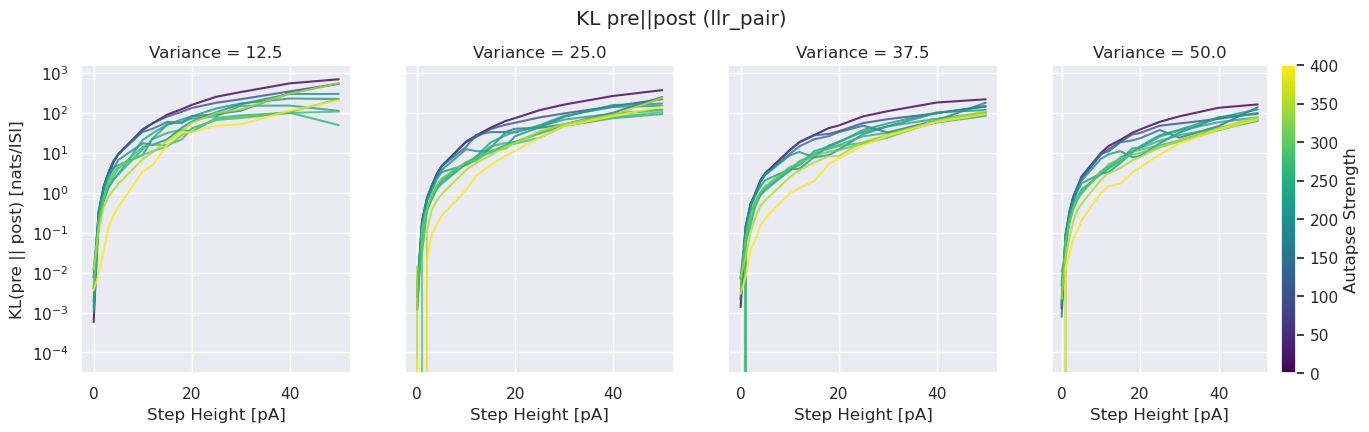

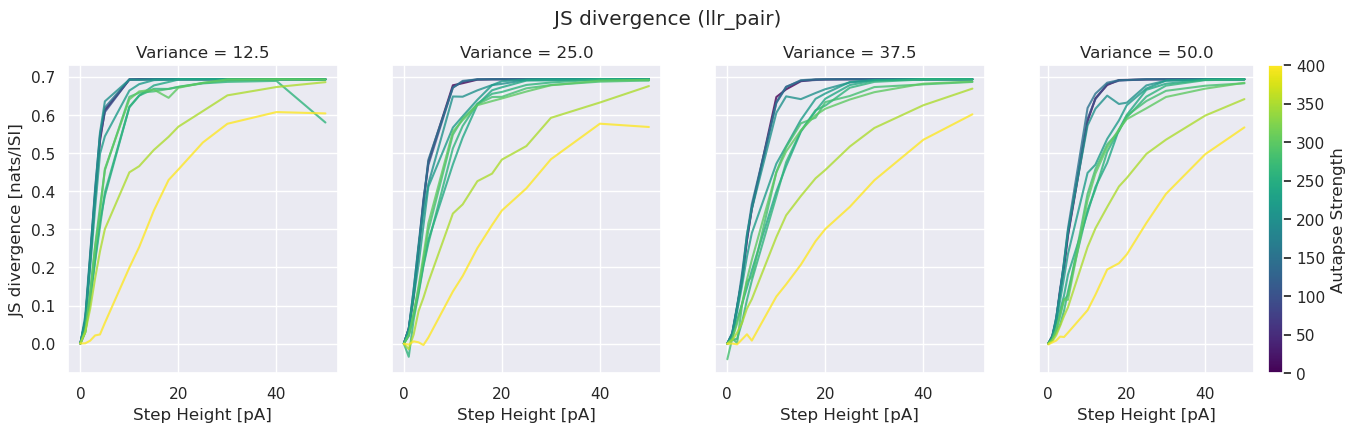

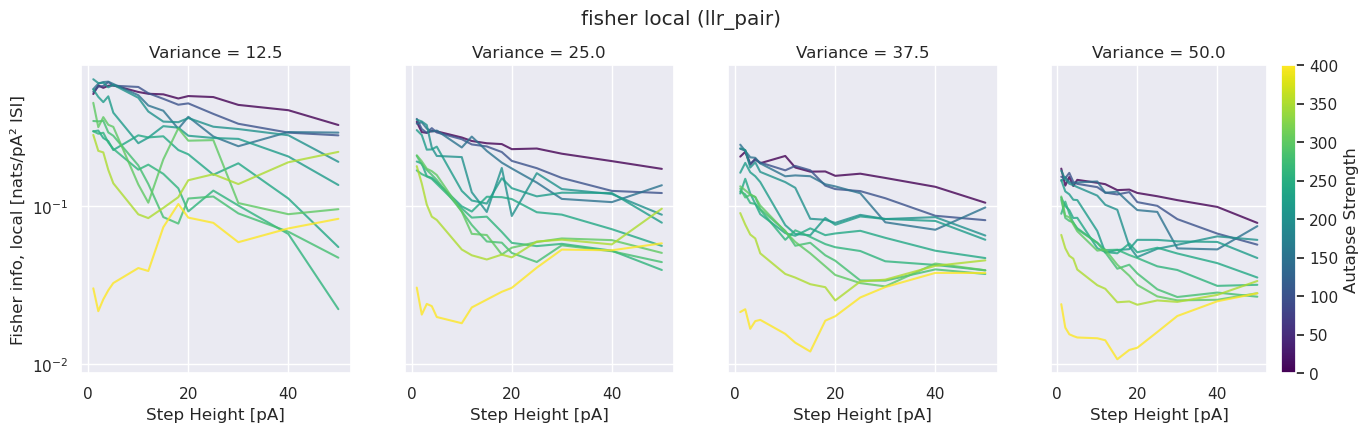

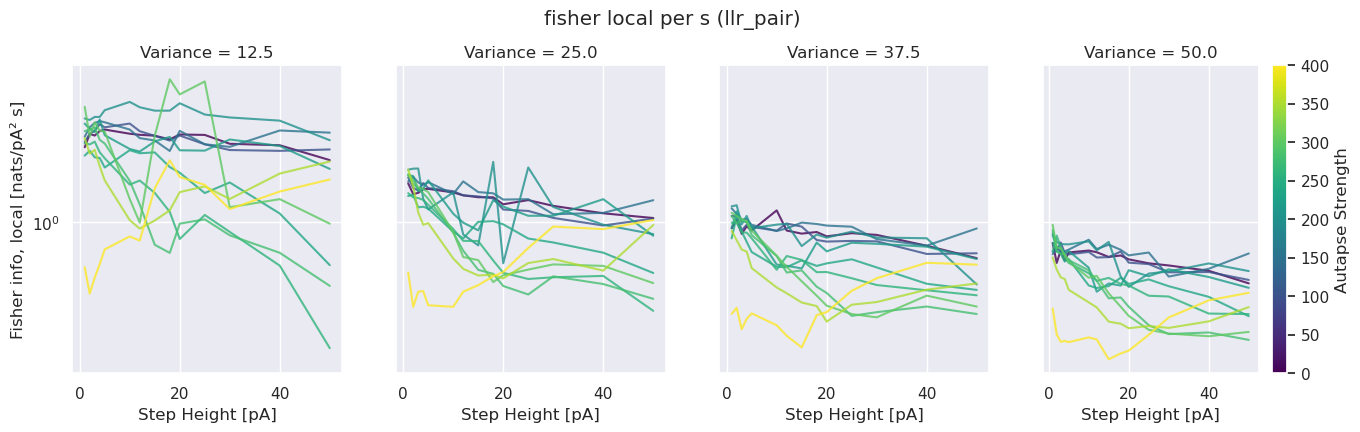

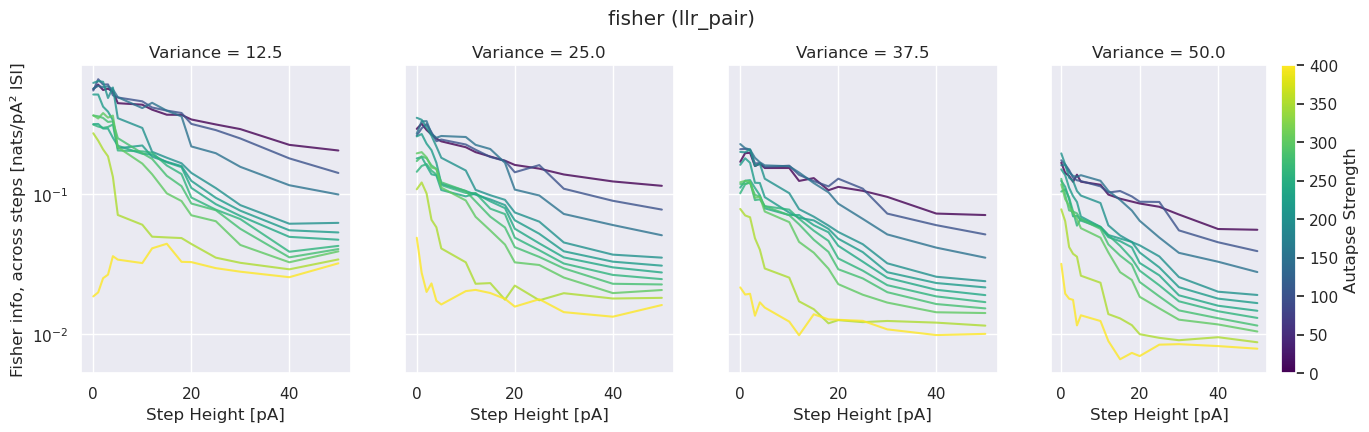

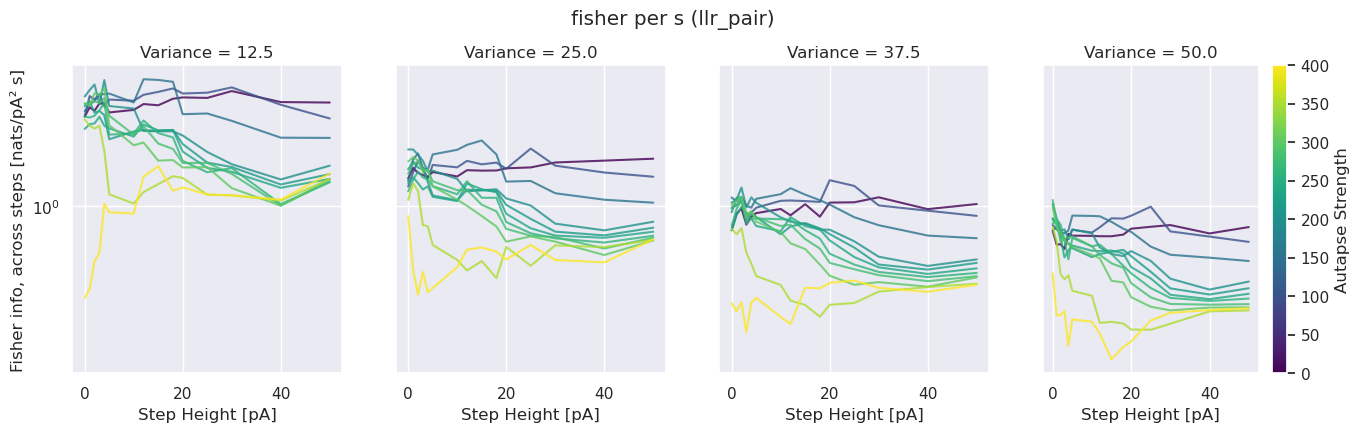

In [33]:
for y, (label, log) in MEASURES.items():
    fig, ax = measure_by_variance(cond, y, label, log)
    if SAVE: plt.savefig(f'./plots/{tag}_{method}_{y.replace(" ", "_").replace("||", "_")}_diff_V.png', bbox_inches = 'tight')
    plt.show()

#### Each measure against step height, one panel per neuron
Lines are noise levels.

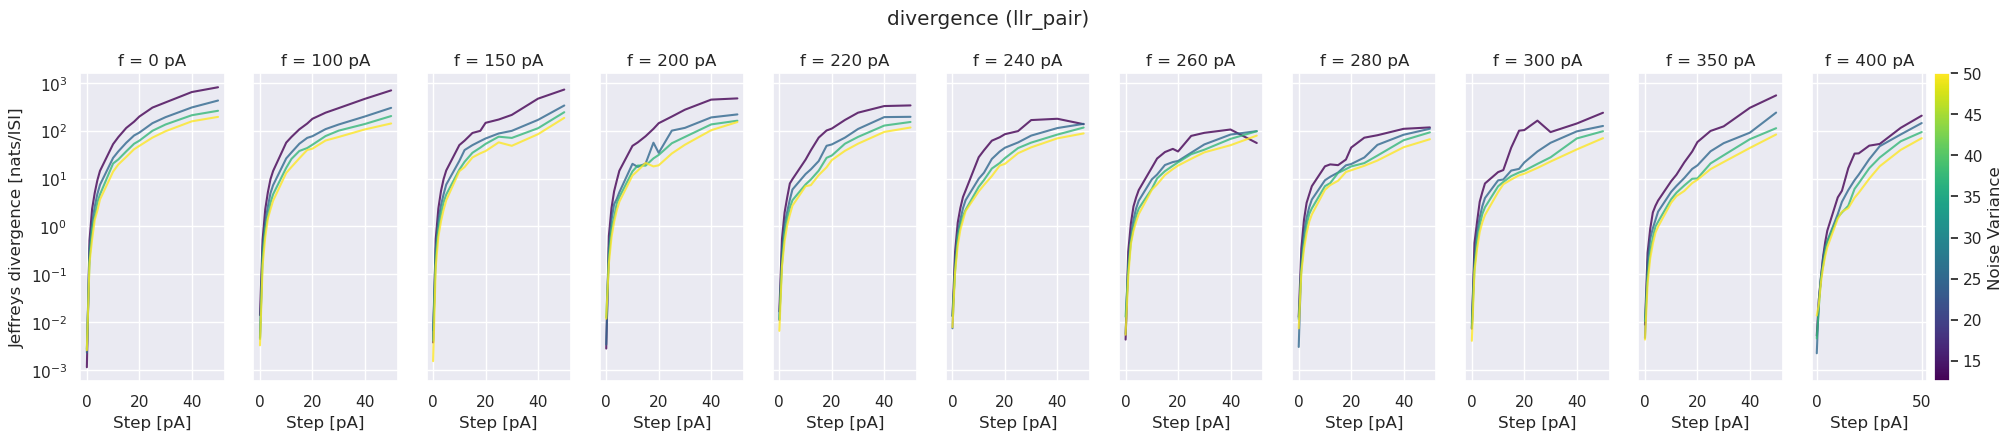

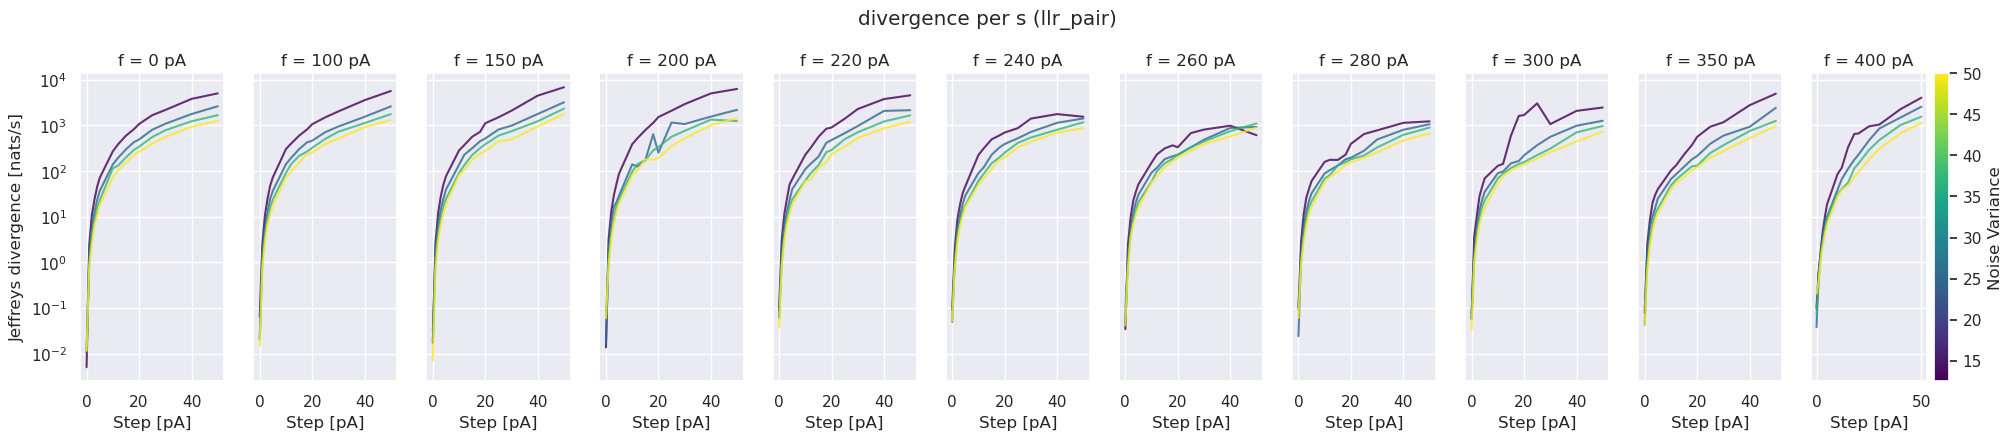

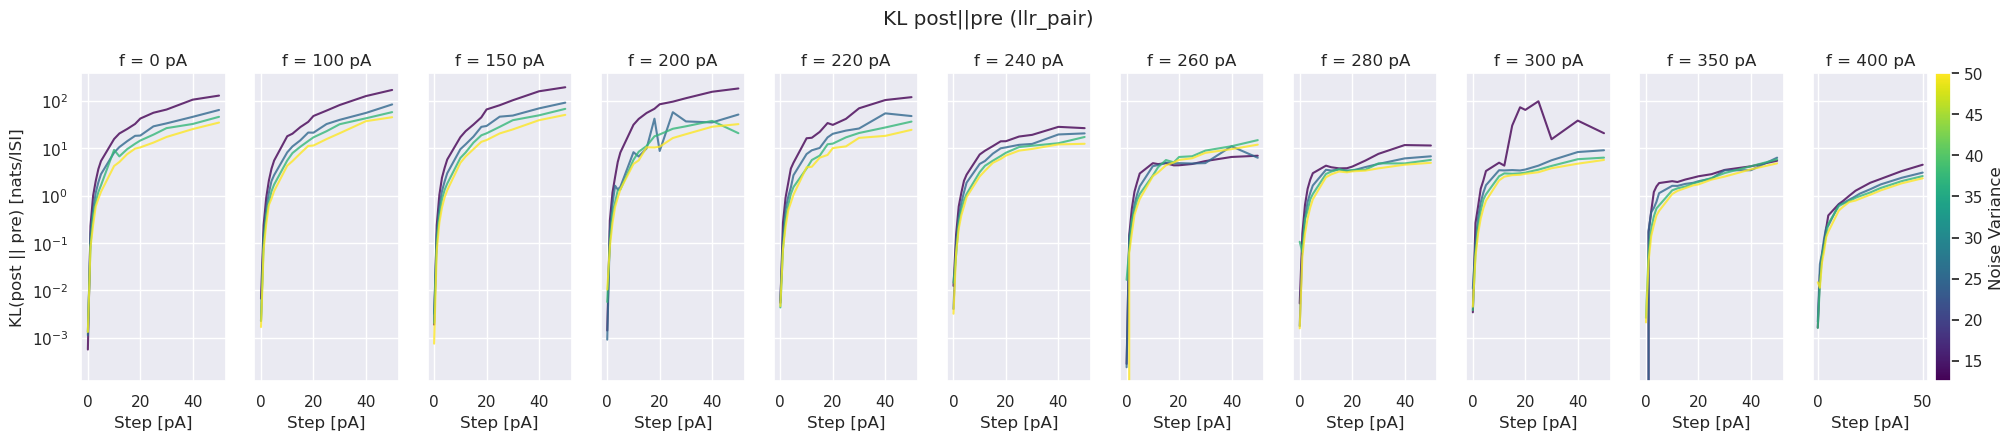

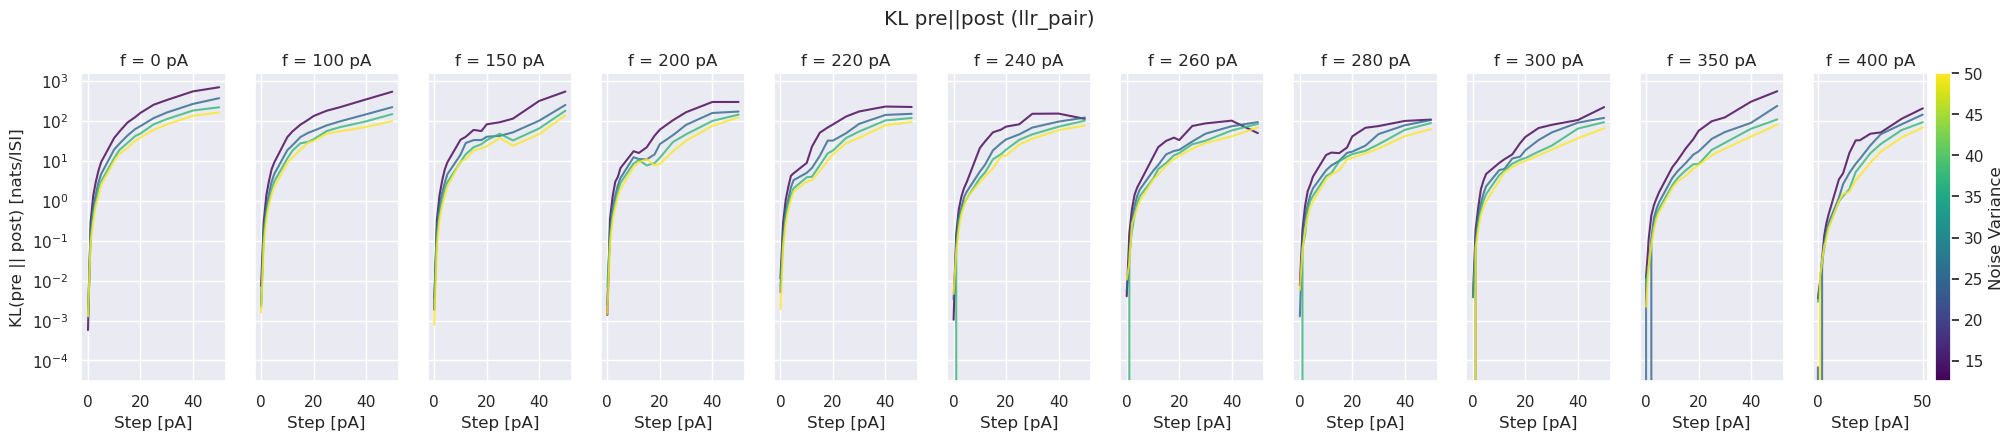

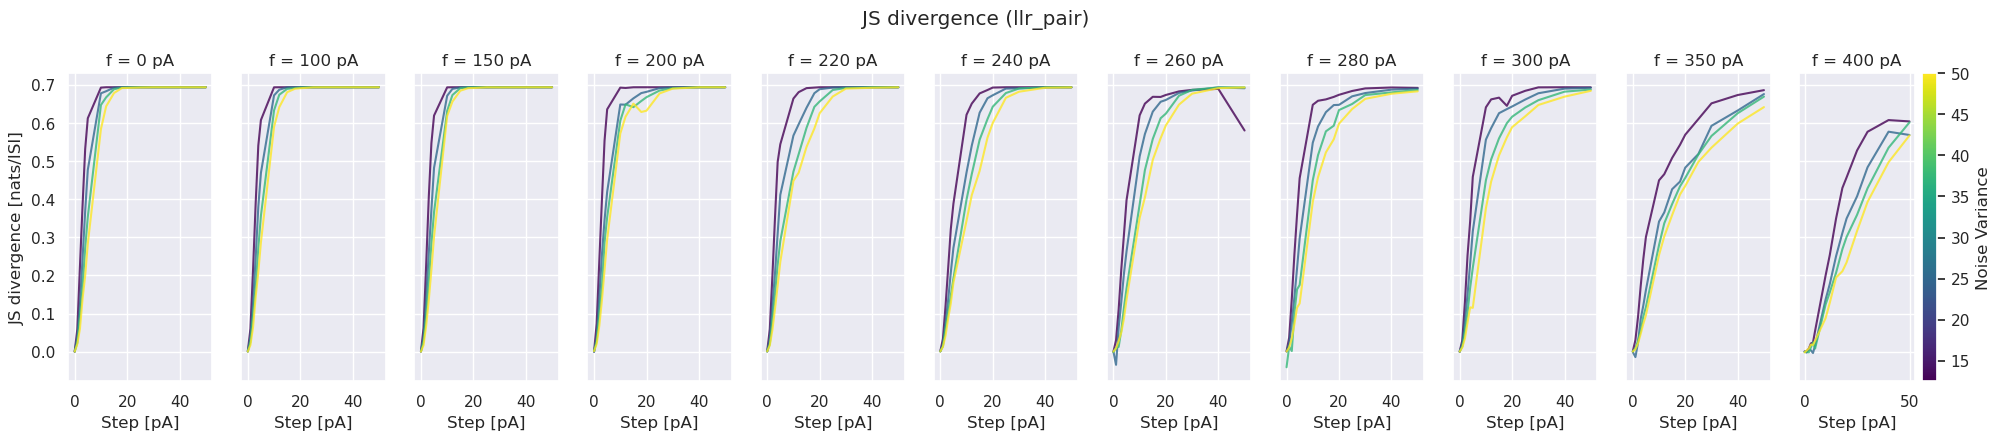

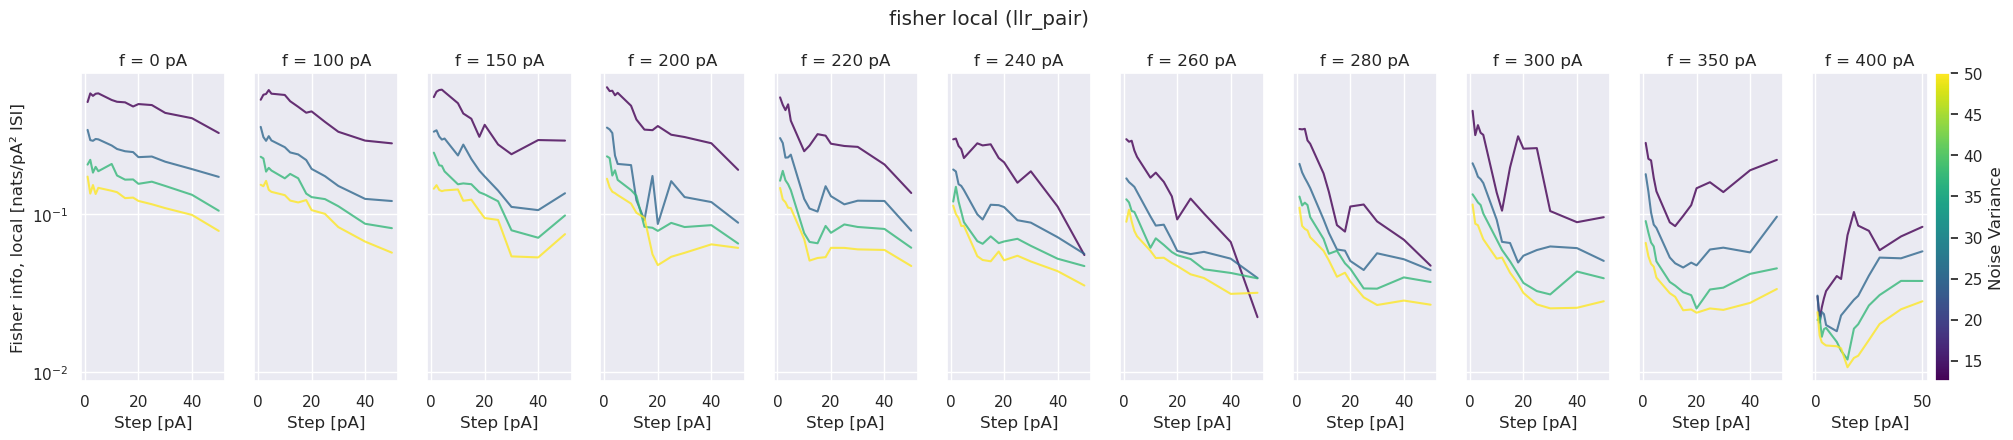

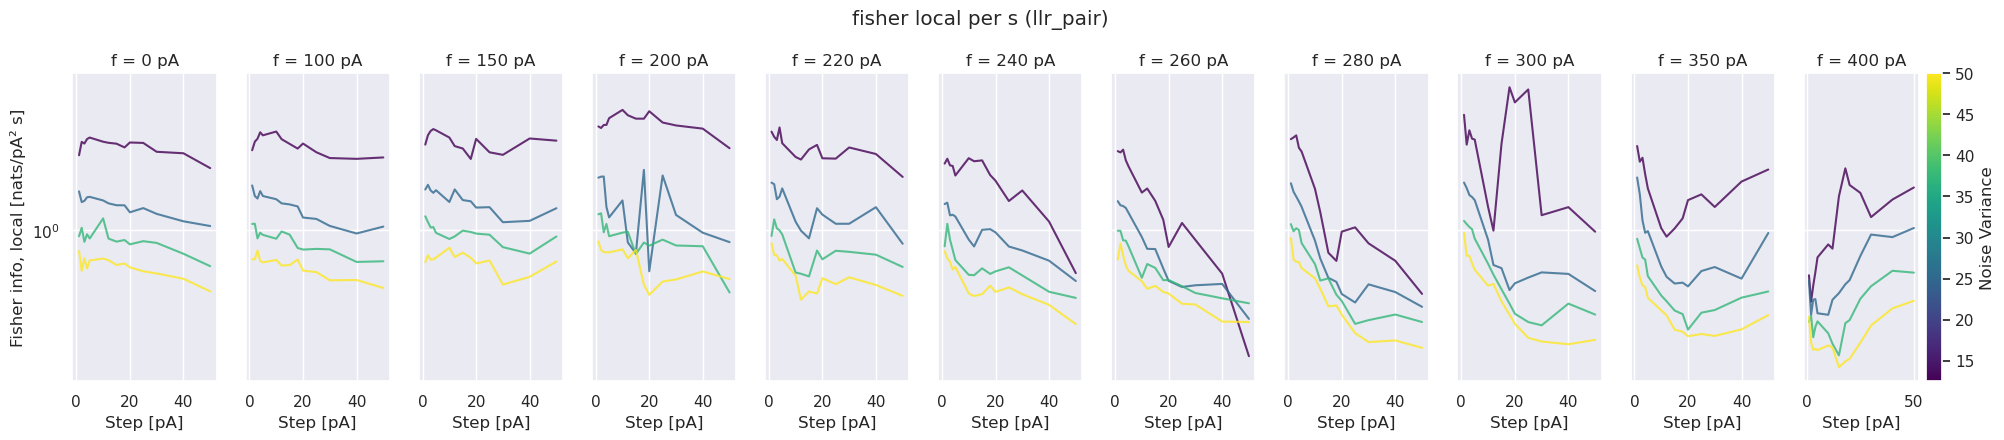

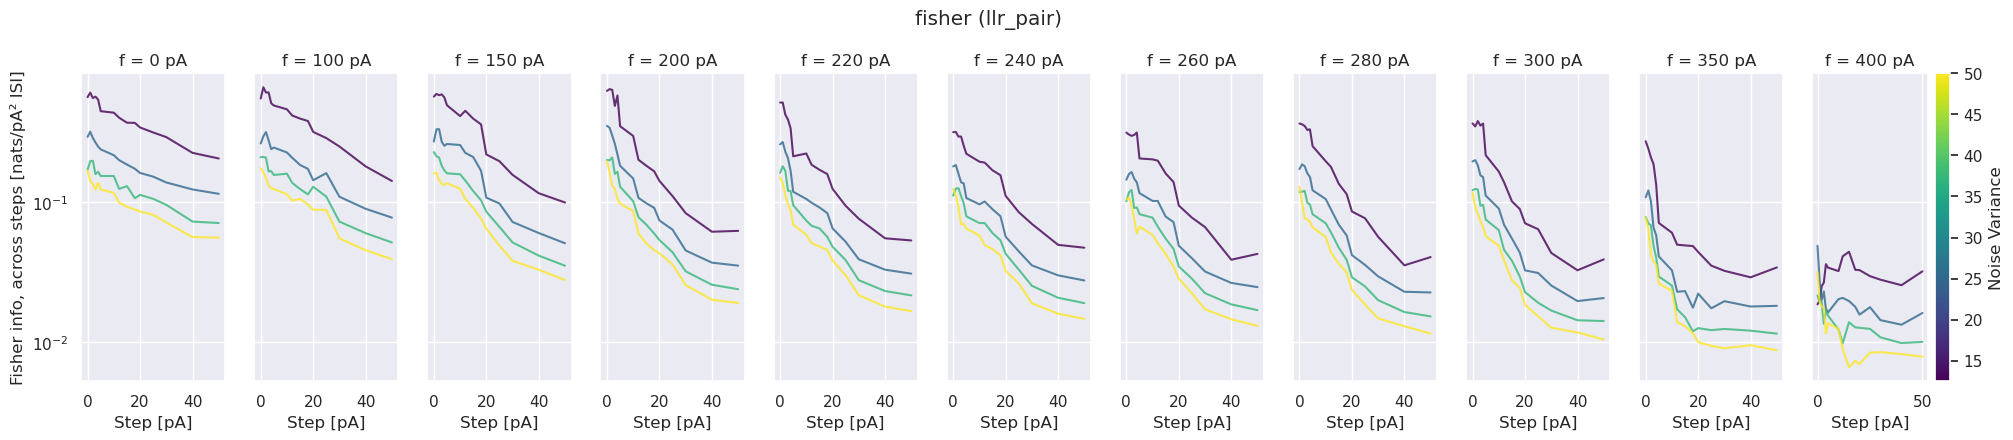

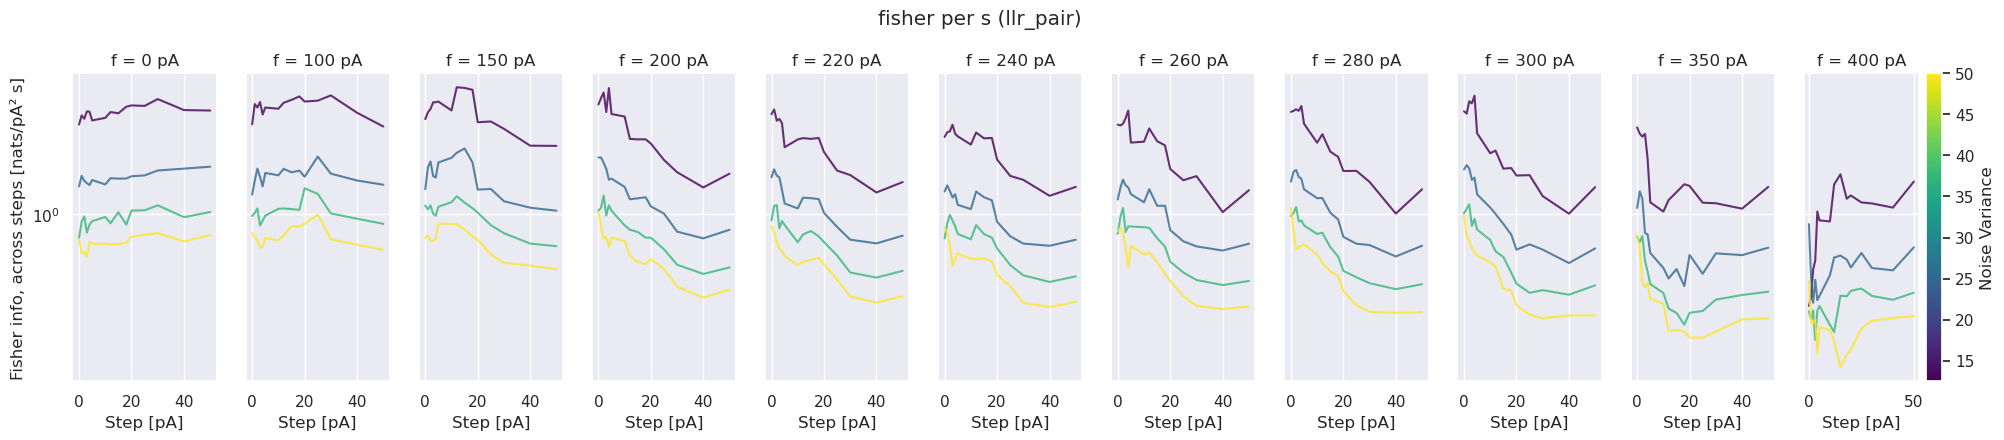

In [34]:
for y, (label, log) in MEASURES.items():
    fig, ax = measure_by_neuron(cond, y, label, log)
    if SAVE: plt.savefig(f'./plots/{tag}_{method}_{y.replace(" ", "_").replace("||", "_")}_diff_autapse.png', bbox_inches = 'tight')
    plt.show()

#### Area under each curve against autapse strength
Uses the same `curve_auc` / `auc_plot` as `AQUA_CPA_plots_CUSUM_mean.ipynb`, with one curve per (f, variance). With `normalise = True` this is the measure's mean over step heights. There is one value per condition, so there is no error band.

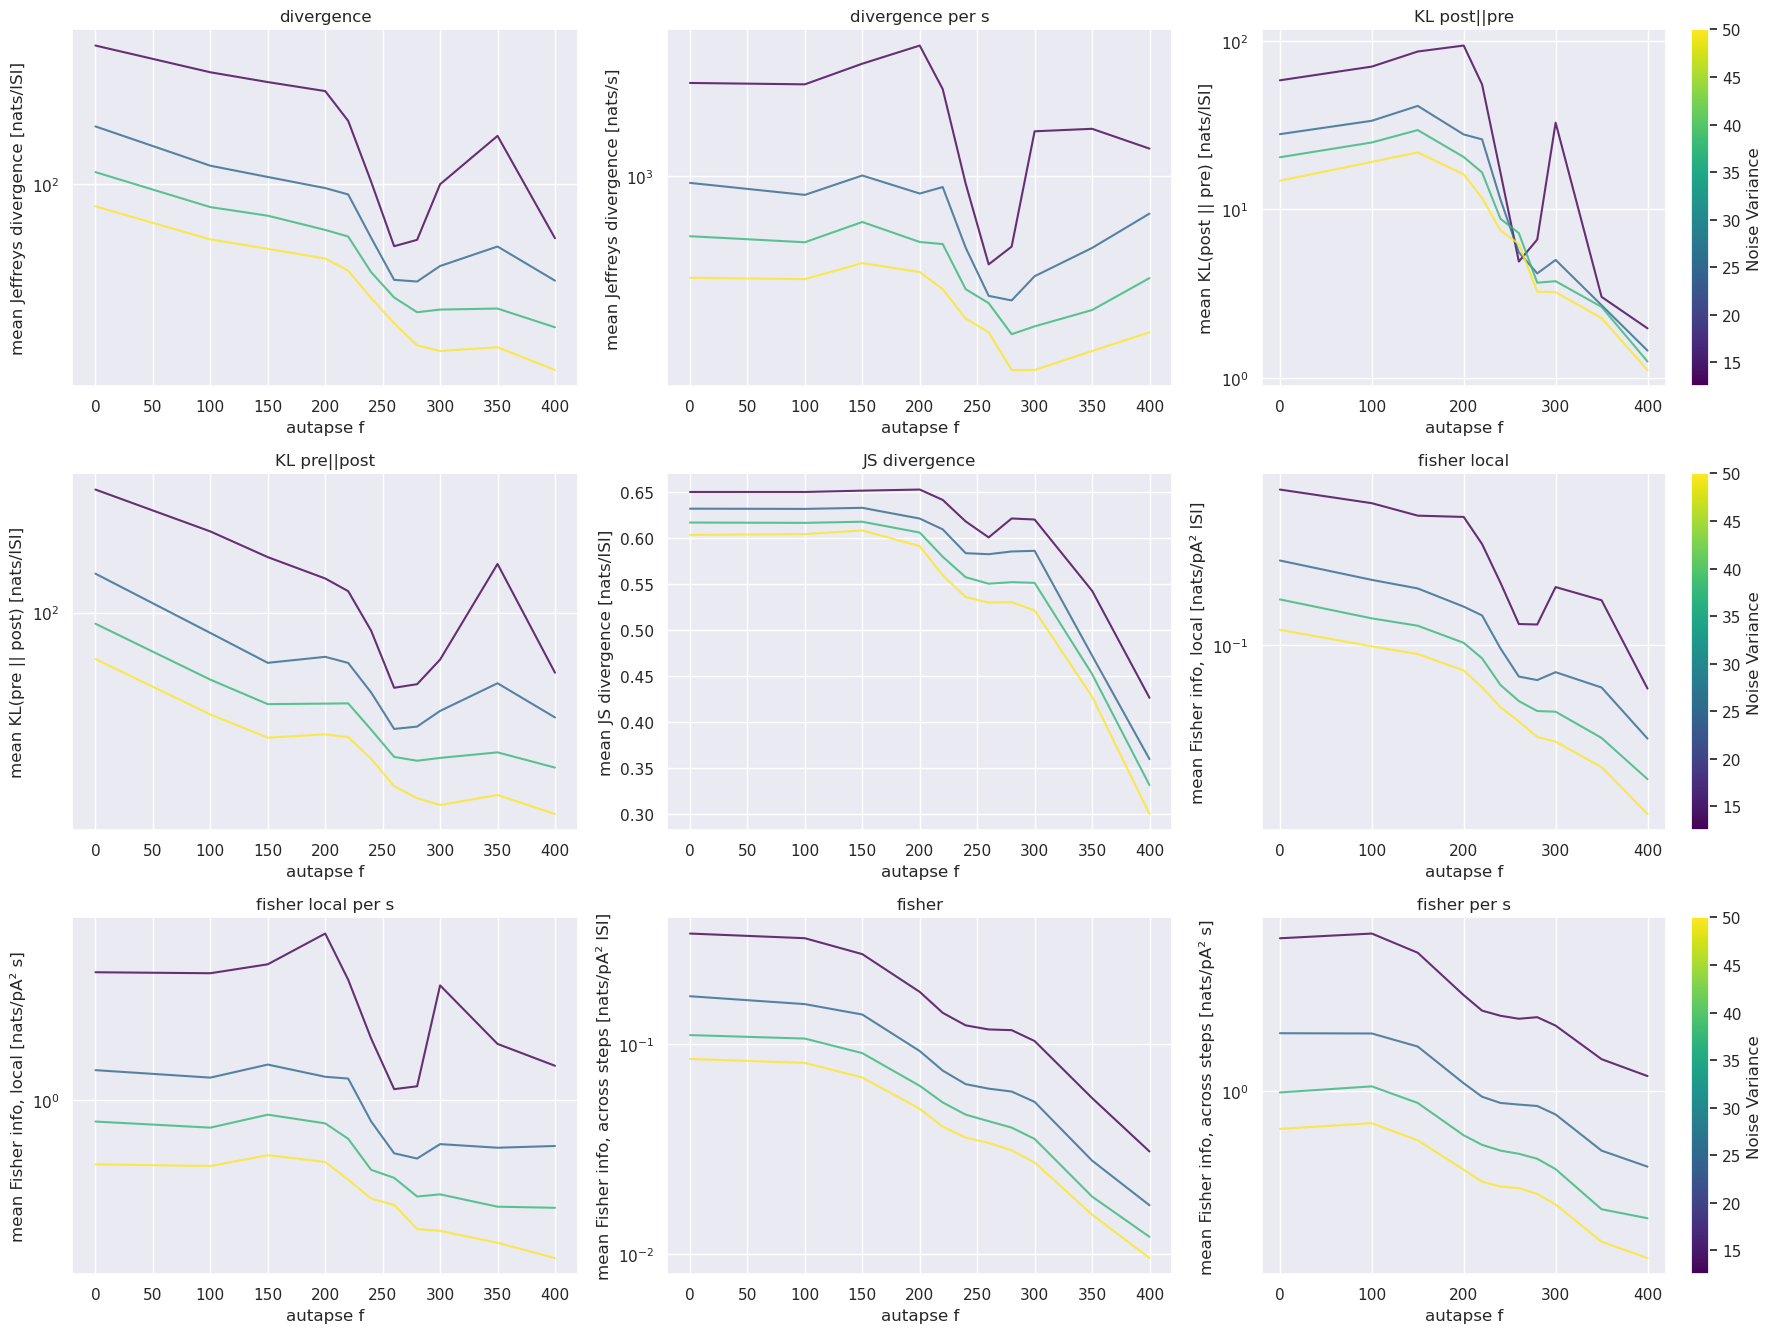

In [35]:
ys = list(MEASURES)
fig, ax = plt.subplots(int(np.ceil(len(ys)/3)), 3, figsize = (18, 4.5*np.ceil(len(ys)/3)), squeeze = False)
ax = ax.ravel()
for n, y in enumerate(ys):
    sub = cond.dropna(subset = [y])
    auc = curve_auc(sub, y = y, group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(auc, fig = fig, ax = ax[n], errorbar = None, add_colorbar = n % 3 == 2)
    ax[n].set_title(y)
    ax[n].set_ylabel(f'mean {MEASURES[y][0]}')
    if MEASURES[y][1]:
        ax[n].set_yscale('log')
for a in ax[len(ys):]:
    a.set_visible(False)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_{method}_divergence_AUC_vs_f.png', bbox_inches = 'tight')

#### Divergence maps (autapse f × step height)
JS divergence is bounded (ln 2 = fully separable), so it can be compared directly across conditions.

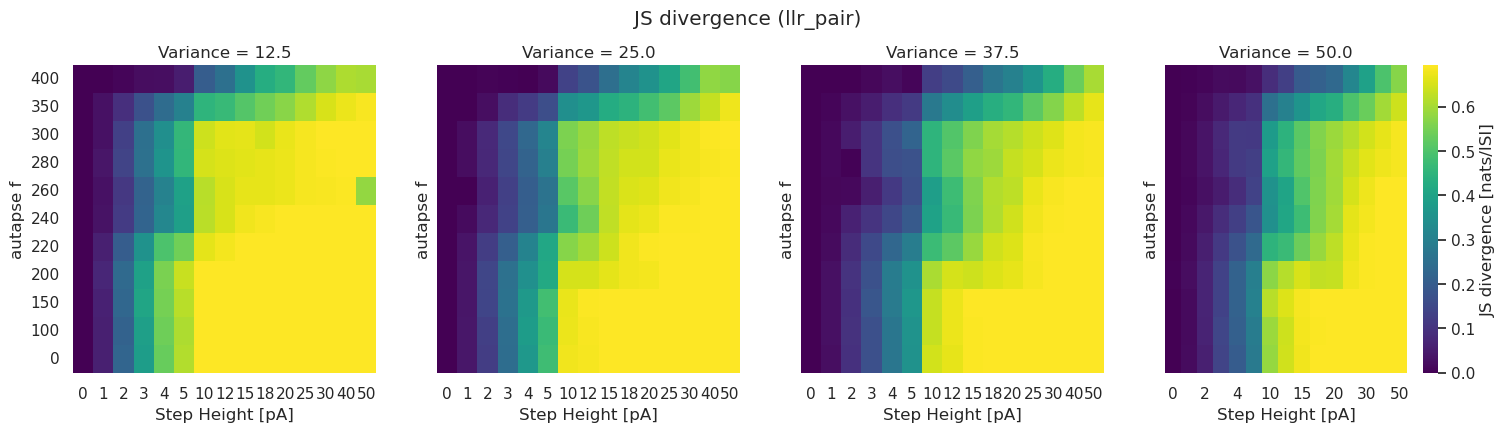

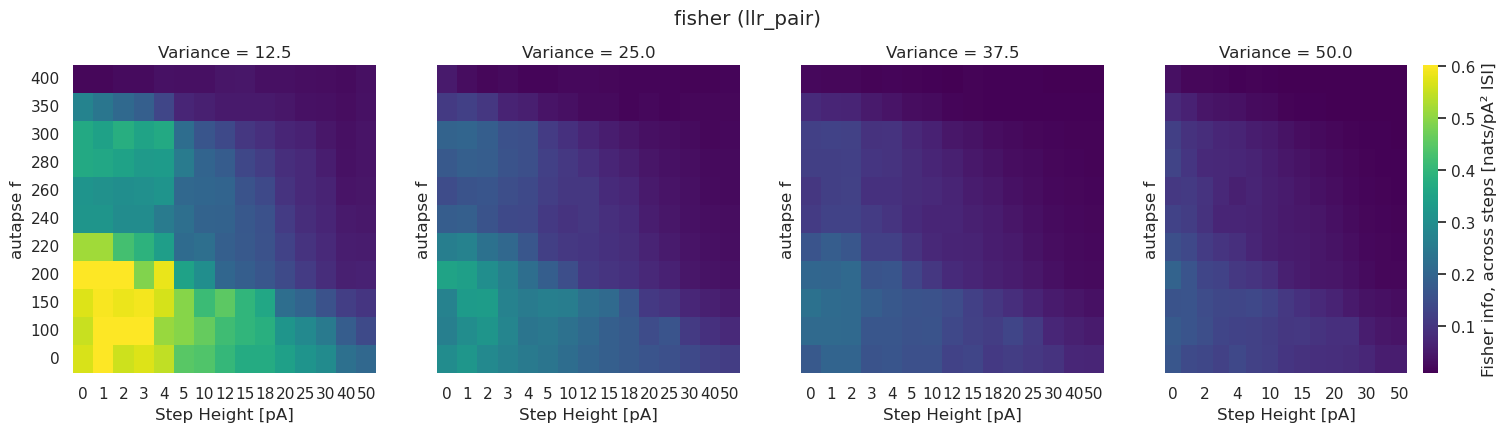

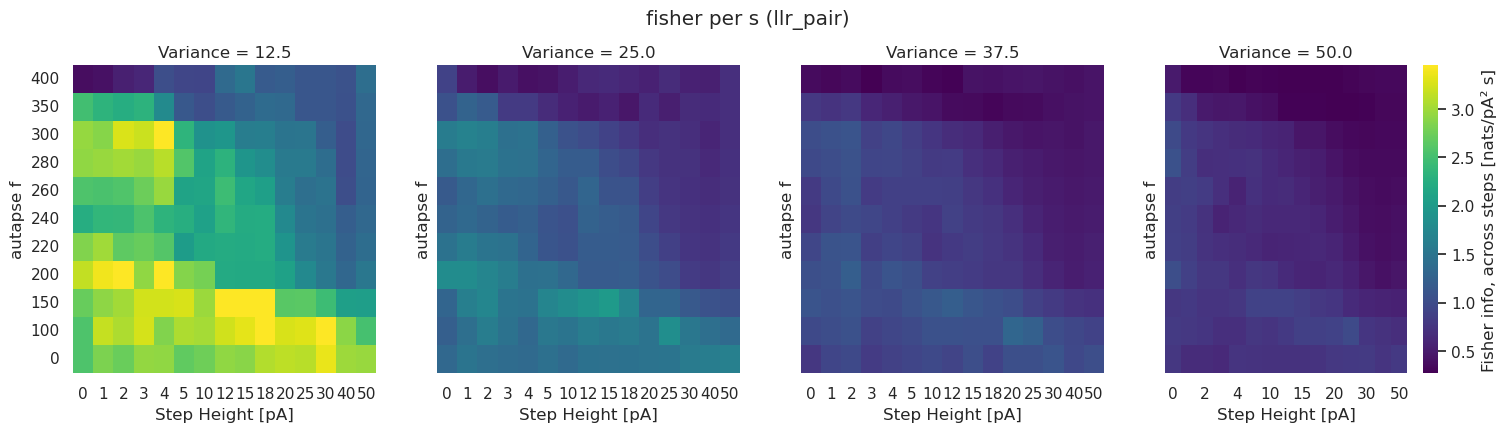

In [36]:
for y in ['JS divergence', 'fisher', 'fisher per s']:
    fig, ax = plt.subplots(1, len(variances), figsize = (4.5*len(variances), 4), sharey = True, squeeze = False)
    ax = ax[0]
    vmin, vmax = np.nanpercentile(cond[y], [1, 99])
    for n, v in enumerate(variances):
        m = cond[cond['variance'] == v].pivot(index = 'autapse f', columns = 'step_height', values = y)
        sns.heatmap(m, ax = ax[n], cmap = 'viridis', vmin = vmin, vmax = vmax, cbar = n == len(variances) - 1,
                    cbar_kws = {'label': MEASURES[y][0]})
        ax[n].invert_yaxis()
        ax[n].set_title(f'Variance = {v}')
        ax[n].set_xlabel('Step Height [pA]')
    fig.suptitle(f'{y} ({method})', y = 1.02)
    if SAVE: plt.savefig(f'./plots/{tag}_{method}_{y.replace(" ", "_")}_map.png', bbox_inches = 'tight')
    plt.show()

#### Checks
1. **Local vs across-step Fisher information.** They should agree for small h. The local estimate J / h² averages over the whole interval [I_0, I_0 + h], so it drifts away as h grows.
2. **Evidence collected vs available.** `score per s` (per trial, measured at the estimated CP) against `divergence per s` (from the fitted distributions). Points below the diagonal mean the CUSUM collects less evidence than the fits predict.

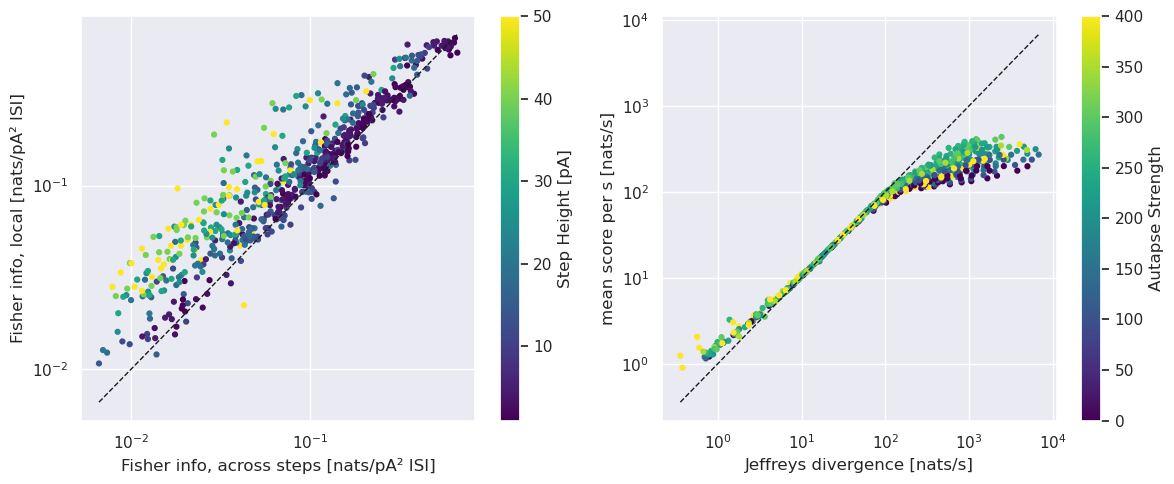

In [37]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))

sub = cond[cond['step_height'] > 0]
sc = ax[0].scatter(sub['fisher'], sub['fisher local'], c = sub['step_height'], cmap = 'viridis', s = 12)
lims = [np.nanmin(sub[['fisher', 'fisher local']].values), np.nanmax(sub[['fisher', 'fisher local']].values)]
ax[0].plot(lims, lims, 'k--', lw = 1)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('Fisher info, across steps [nats/pA² ISI]')
ax[0].set_ylabel('Fisher info, local [nats/pA² ISI]')
fig.colorbar(sc, ax = ax[0], label = 'Step Height [pA]')

# realised evidence: average the per-trial score per s over repeats
ev = data.groupby(cond_cols, as_index = False)[['score per s', 'divergence per s']].mean()
ev = ev[ev['step_height'] > 0]
sc = ax[1].scatter(ev['divergence per s'], ev['score per s'], c = ev['autapse f'], cmap = 'viridis', s = 12)
lims = [max(np.nanmin(ev['divergence per s']), 1e-3), np.nanmax(ev['divergence per s'])]
ax[1].plot(lims, lims, 'k--', lw = 1)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('Jeffreys divergence [nats/s]')
ax[1].set_ylabel('mean score per s [nats/s]')
fig.colorbar(sc, ax = ax[1], label = 'Autapse Strength')
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_{method}_divergence_checks.png', bbox_inches = 'tight')

### Model-free distances between the pooled pre and post ISIs

All the measures above come from the **fitted** pre/post distributions, so a fall with f could come from the fits getting worse rather than from the ISI distributions overlapping more. The distances below compare the empirical (pooled) ISIs directly, with no model:

| Column | Meaning |
|---|---|
| `KS distance` | two-sample KS statistic (largest gap between the two ECDFs), 0-1 |
| `energy distance` | energy distance of the ISIs [ms]. Scales with the ISIs, so it shrinks for neurons that fire faster |
| `energy distance (log)` | energy distance of log(ISI), scale-free |

These only use the 1D ISI distributions, so they ignore the ISI-pair (burst) structure that `llr_pair` models.
If KS and log-energy also fall with f, the "broader distributions" explanation does not depend on the fits.

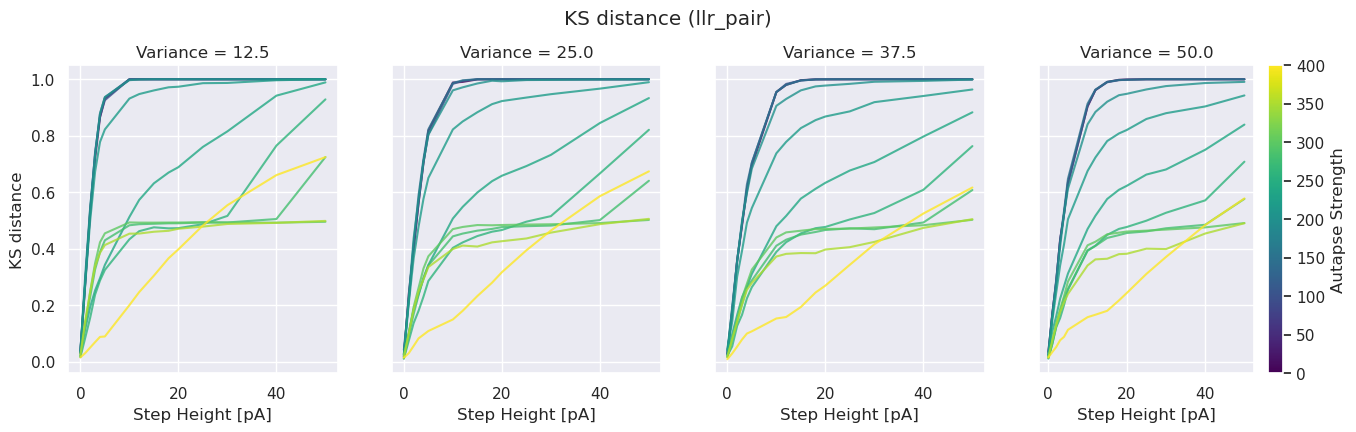

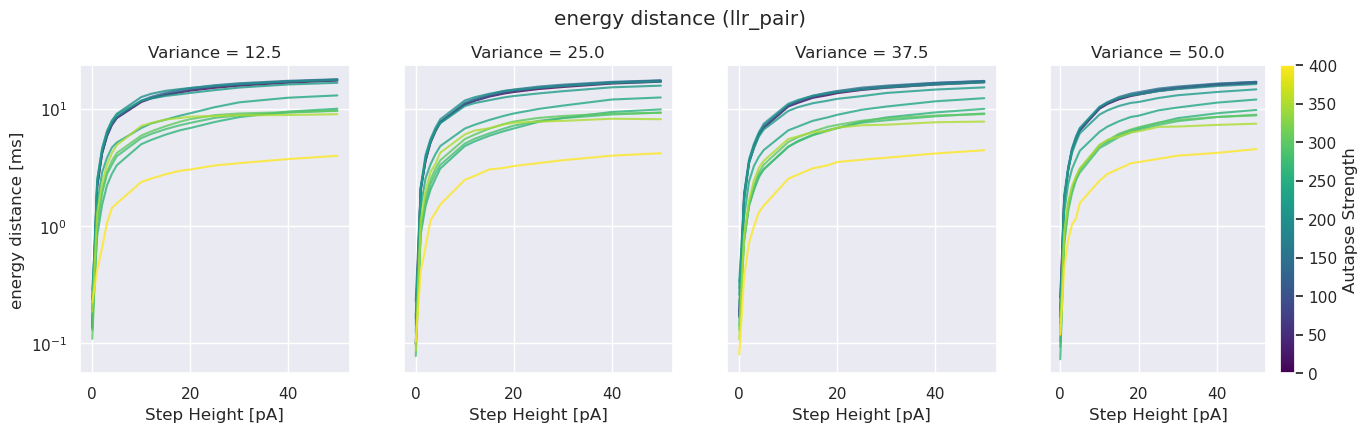

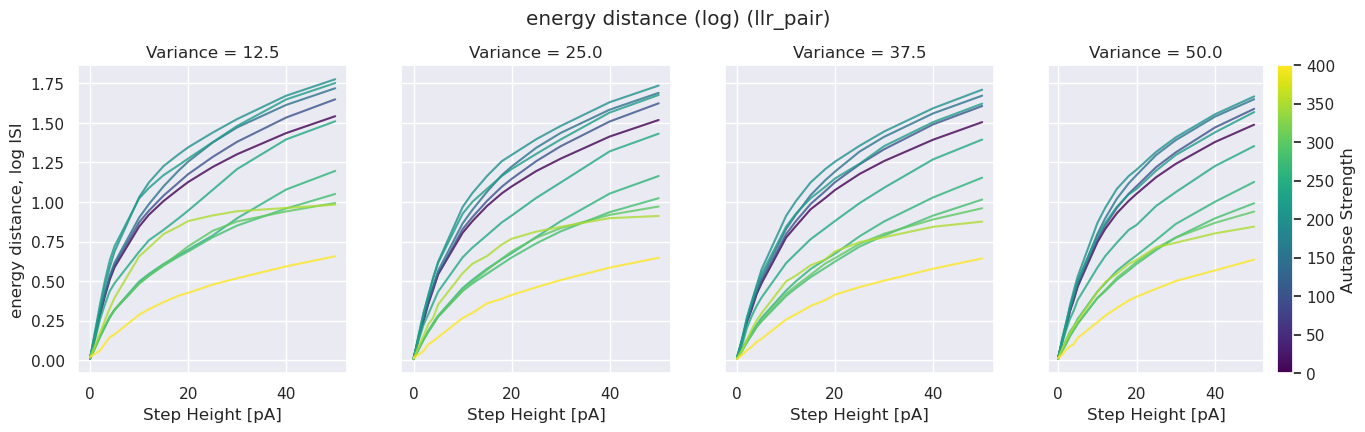

In [38]:
EMPIRICAL = {
    'KS distance':           ('KS distance', False),
    'energy distance':       ('energy distance [ms]', True),
    'energy distance (log)': ('energy distance, log ISI', False),
}

for y, (label, log) in EMPIRICAL.items():
    fig, ax = measure_by_variance(cond, y, label, log)
    if SAVE: plt.savefig(f'./plots/{tag}_{y.replace(" ", "_")}_diff_V.png', bbox_inches = 'tight')
    plt.show()

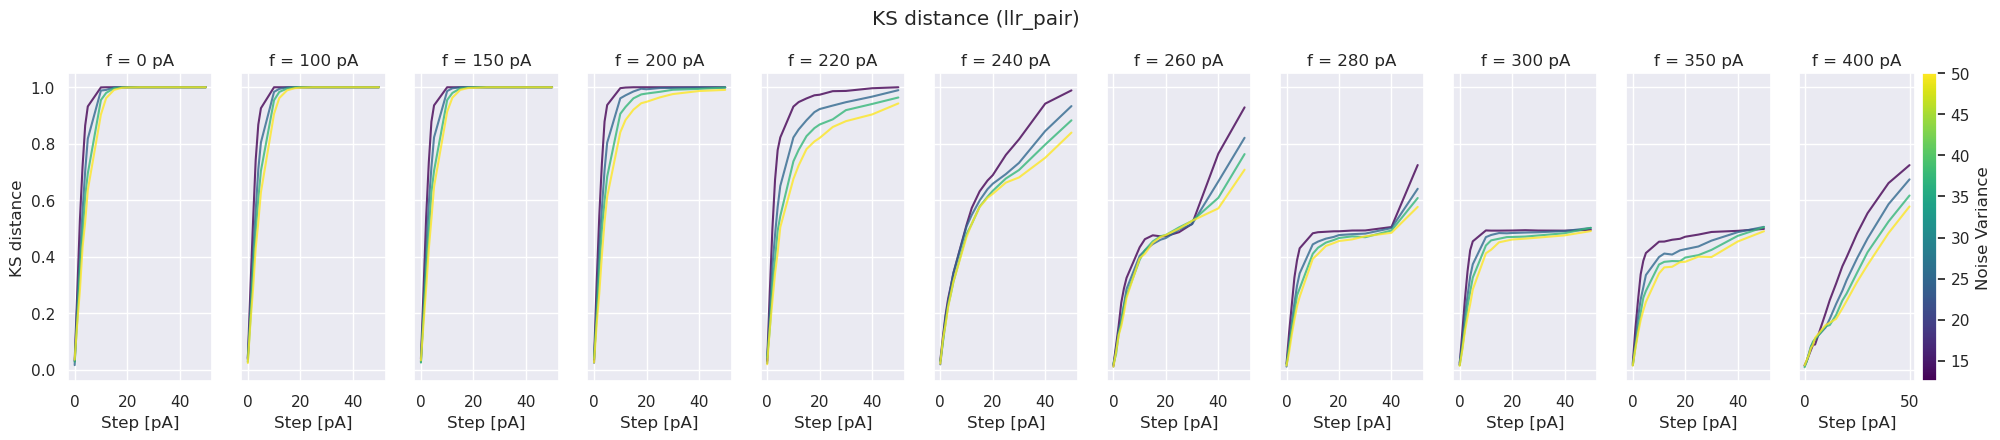

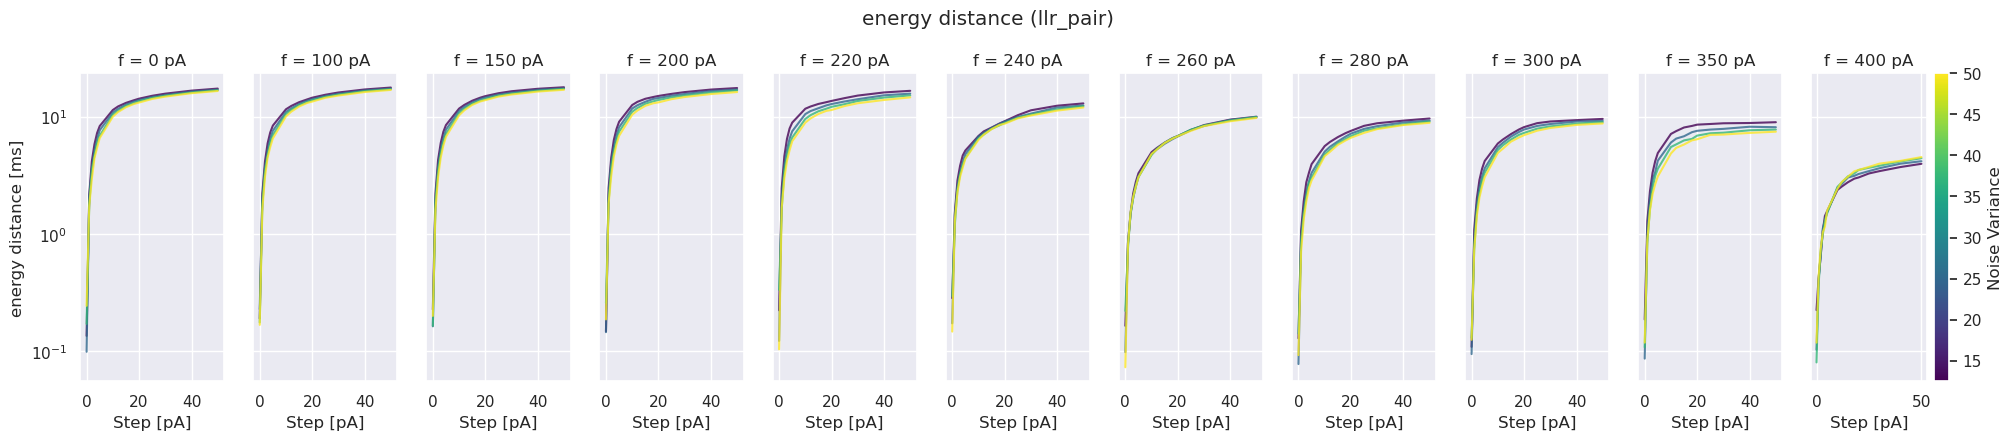

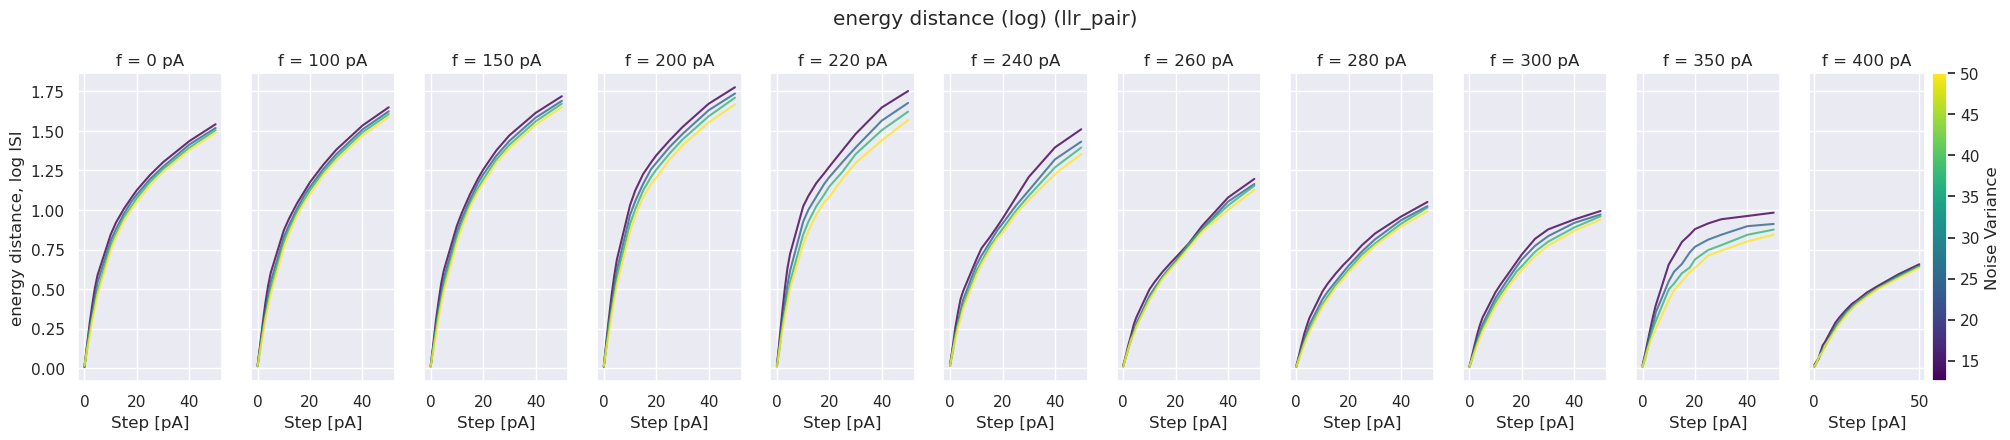

In [39]:
for y, (label, log) in EMPIRICAL.items():
    fig, ax = measure_by_neuron(cond, y, label, log)
    if SAVE: plt.savefig(f'./plots/{tag}_{y.replace(" ", "_")}_diff_autapse.png', bbox_inches = 'tight')
    plt.show()

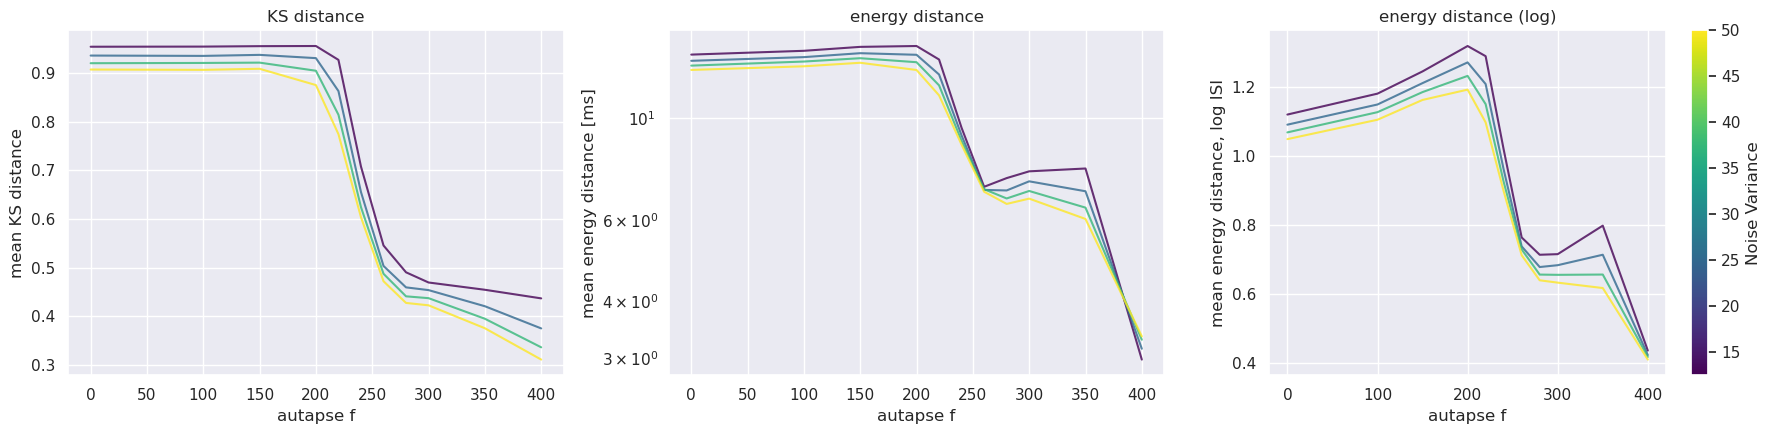

In [40]:
## mean over step heights against autapse strength
fig, ax = plt.subplots(1, len(EMPIRICAL), figsize = (6*len(EMPIRICAL), 4.5), squeeze = False)
ax = ax[0]
for n, (y, (label, log)) in enumerate(EMPIRICAL.items()):
    auc = curve_auc(cond.dropna(subset = [y]), y = y, group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(auc, fig = fig, ax = ax[n], errorbar = None, add_colorbar = n == len(EMPIRICAL) - 1)
    ax[n].set_title(y)
    ax[n].set_ylabel(f'mean {label}')
    if log:
        ax[n].set_yscale('log')
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_empirical_distance_AUC_vs_f.png', bbox_inches = 'tight')

#### Model-free vs fitted measures
Each point is one condition (h > 0), coloured by autapse strength. If the fits were the problem for high f, the high-f points would sit away from the low-f ones (e.g. a lower JS for the same KS).

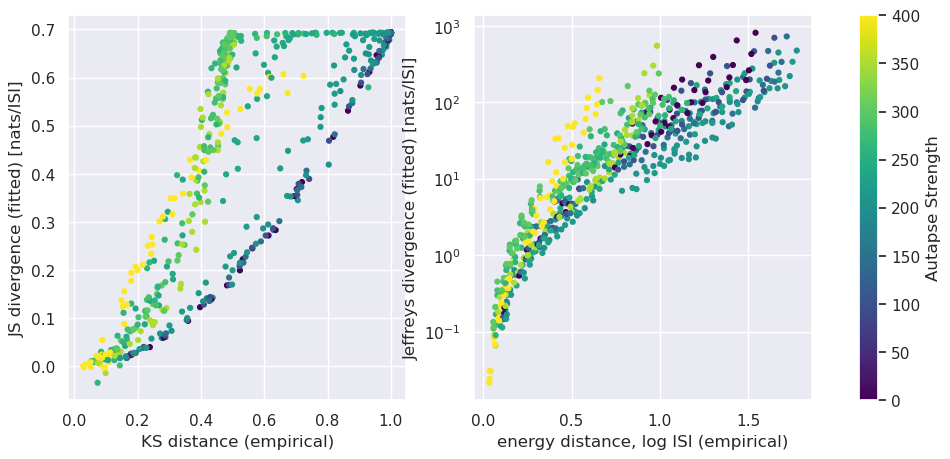

In [41]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))
sub = cond[cond['step_height'] > 0]

sc = ax[0].scatter(sub['KS distance'], sub['JS divergence'], c = sub['autapse f'], cmap = 'viridis', s = 12)
ax[0].set_xlabel('KS distance (empirical)')
ax[0].set_ylabel('JS divergence (fitted) [nats/ISI]')

sc = ax[1].scatter(sub['energy distance (log)'], sub['divergence'], c = sub['autapse f'], cmap = 'viridis', s = 12)
ax[1].set_yscale('log')
ax[1].set_xlabel('energy distance, log ISI (empirical)')
ax[1].set_ylabel('Jeffreys divergence (fitted) [nats/ISI]')

fig.colorbar(sc, ax = ax, label = 'Autapse Strength')
if SAVE: plt.savefig(f'./plots/{tag}_{method}_empirical_vs_fitted.png', bbox_inches = 'tight')